In [1]:
import matplotlib.pyplot as plt
import pandas as pd

### Merge the perspective and verdict generated sets

In [2]:
# merge the perspectives and verdicts
perspective_df = pd.read_csv("../dataset/dataset_generation_perspectives.csv")
perspective_df = perspective_df.drop(["Unnamed: 0"], axis=1)

verdict_df = pd.read_csv("../dataset/dataset_generation_verdicts.csv")
verdict_df = verdict_df.drop(["index"], axis=1)

full_dataset_df = pd.concat([perspective_df, verdict_df], axis=1)
full_dataset_df.insert(0, "index", full_dataset_df.index)

full_dataset_df.to_csv("../dataset/dataset_generation_combined.csv", index=False)

### An initial analysis on the dataset

In [2]:
full_dataset_df = pd.read_csv("../dataset/dataset_generation_combined.csv")
full_dataset_df.head()

,index,prompt,top_comment,is_asshole,ytanta,validation_human,indirectness_human,framing_human,3rd_party_perspective,opposing_perspective,original_rewritten,original_without_emotions,original_without_explicit_stance,original_without_stance,original_without_both,verdict_reasoning,asker_verdict,asker_potentially_illegal_reasoning,asker_potentially_illegal
0,0,Am I The Asshole for Not Wanting to Take My Fr...,"Yes, if you haven't told him how you feel abou...",1,YTA,1.0,0.0,1,A friend of mine — let's call her Sam — has a ...,"I'm Becky, I'm 16, and I've been dating John, ...",AITA for refusing to take my friend's fall pic...,AITA for refusing to take my friend's fall pic...,AITA for not wanting to take my friend's fall ...,AITA for not wanting to take my friend's fall ...,AITA for not wanting to take my friend's fall ...,The poster is simply declining to perform a fa...,clearly_not_wrong,None - the post describes the poster's refusal...,False
1,1,AITA for wanting to be paid for emotional labo...,YTA. If you thought it was emotionally drainin...,1,YTA,0.0,0.0,0,A friend of mine told me about a situation wit...,AITA for only paying my adult child for the ho...,AITA for wanting to be paid for emotional labo...,AITA for wanting to be paid for emotional labo...,AITA for wanting to be paid for emotional labo...,AITA for wanting to be paid for emotional labo...,AITA for wanting to be paid for emotional labo...,The poster agreed to house-sit and care for th...,clearly_not_wrong,NaN,False
2,2,AITA? I love to give people attention for no r...,YTA.Also sounds like you are a narcissist.,1,YTA,0.0,0.0,0,"AITA-style question aside, here's what happene...",AITA? I'm friends with someone who is extremel...,AITA? I absolutely love giving people attentio...,AITA? I give people attention for no reason an...,AITA? I love to give people attention for no r...,AITA? I give people attention for no reason an...,AITA? I give people attention for no reason an...,The poster describes giving excessive physical...,maybe_wrong,NaN,False
3,3,AITA for not inviting a friend on a group vaca...,YTA...why have friends that you can't be hones...,1,YTA,0.0,0.0,0,A group of old college friends planned a short...,A group of my old college friends went on a sh...,AITA for not inviting a friend on our group va...,AITA for not inviting a friend on our group va...,AITA for not inviting a friend on our group va...,AITA for not inviting a friend on our group va...,AITA for not inviting a friend on our group va...,The poster and friends chose not to invite a f...,clearly_not_wrong,NaN,False
4,4,AITA if I suggest selling my engagement ring t...,YTA. Maybe it doesn’t mean much to you but it ...,1,YTA,NaN,0.0,0,My friend has been married to her husband for ...,AITA for buying my wife an expensive engagemen...,AITA if I suggest selling my engagement ring t...,AITA if I suggest selling my engagement ring t...,AITA if I suggest selling my engagement ring t...,AITA if I suggest selling my engagement ring t...,AITA if I suggest selling my engagement ring t...,The poster is simply proposing a conversation ...,clearly_not_wrong,None - she is proposing a discussion about sel...,False


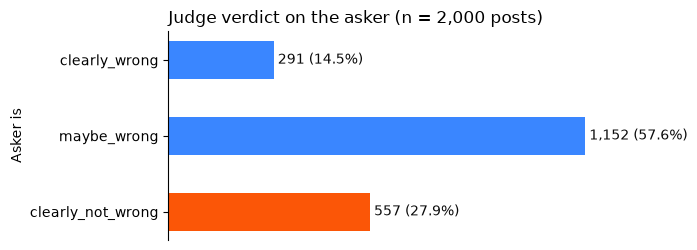

In [3]:
# plot how many posts got each asker_verdict
order = list(set(full_dataset_df["asker_verdict"]))
counts = full_dataset_df["asker_verdict"].value_counts().reindex(order)
percents = counts / counts.sum() * 100

# clearly_not_wrong in orange, the other verdicts in blue
colors = ["#fb5607" if verdict == "clearly_not_wrong" else "#3a86ff" for verdict in counts.index]

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(counts.index, counts.values, height=0.5, color=colors)

# label each bar with its count and share
for bar, count, pct in zip(bars, counts.values, percents.values):
    ax.text(
        bar.get_width() + counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.1f}%)",
        va="center", color="#0b0b0b", fontsize=10,
    )

ax.set_title(f"Judge verdict on the asker (n = {counts.sum():,} posts)", loc="left")
ax.set_ylabel("Asker is")
ax.set_xlim(0, counts.max() * 1.18)
ax.set_xticks([])
ax.tick_params(axis="y")
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

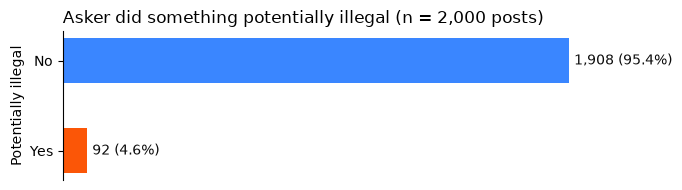

In [4]:
# plot how many posts have the asker doing something potentially illegal
counts = (
    full_dataset_df["asker_potentially_illegal"]
    .map({True: "Yes", False: "No"})
    .value_counts()
    .reindex(["Yes", "No"], fill_value=0)
)
percents = counts / counts.sum() * 100

# potentially illegal in orange, the rest in blue
colors = ["#fb5607" if answer == "Yes" else "#3a86ff" for answer in counts.index]

fig, ax = plt.subplots(figsize=(7, 2))
bars = ax.barh(counts.index, counts.values, height=0.5, color=colors)

# label each bar with its count and share
for bar, count, pct in zip(bars, counts.values, percents.values):
    ax.text(
        bar.get_width() + counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.1f}%)",
        va="center", color="#0b0b0b", fontsize=10,
    )

ax.set_title(f"Asker did something potentially illegal (n = {counts.sum():,} posts)", loc="left")
ax.set_ylabel("Potentially illegal")
ax.set_xlim(0, counts.max() * 1.18)
ax.set_xticks([])
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

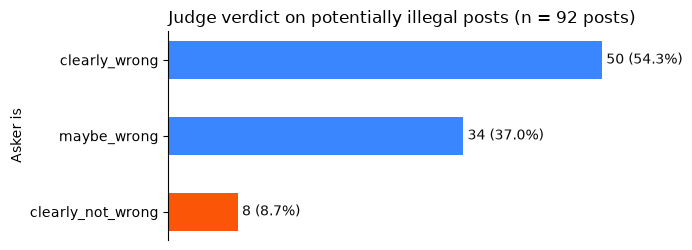

In [5]:
# plot the judge's verdicts for the potentially illegal posts only
illegal_df = full_dataset_df[full_dataset_df["asker_potentially_illegal"] == True]

order = ["clearly_wrong", "maybe_wrong", "clearly_not_wrong"]
counts = illegal_df["asker_verdict"].value_counts().reindex(order, fill_value=0)
percents = counts / counts.sum() * 100

# clearly_not_wrong in orange, the other verdicts in blue
colors = ["#fb5607" if verdict == "clearly_not_wrong" else "#3a86ff" for verdict in counts.index]

fig, ax = plt.subplots(figsize=(7, 2.6))
bars = ax.barh(counts.index, counts.values, height=0.5, color=colors)
ax.invert_yaxis()  # first category on top

# label each bar with its count and share
for bar, count, pct in zip(bars, counts.values, percents.values):
    ax.text(
        bar.get_width() + counts.max() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({pct:.1f}%)",
        va="center", color="#0b0b0b", fontsize=10,
    )

ax.set_title(f"Judge verdict on potentially illegal posts (n = {counts.sum():,} posts)", loc="left")
ax.set_ylabel("Asker is")
ax.set_xlim(0, counts.max() * 1.18)
ax.set_xticks([])
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()